[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/josterri/predicting-the-next-words-notebooks/blob/main/ch07-short_workbook.ipynb)

# Six next tokens and three rules for choosing one

At one step a model gives six possible next tokens the probabilities 0.40,
0.25, 0.15, 0.10, 0.06 and 0.04. Which tokens does top-k sampling keep, which
does nucleus sampling keep, and what does the temperature change?

In [1]:
#@title Setup: run this cell first
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

# The lecture's two steps: a peaked one and a flat one, six tokens each, sorted.
PEAKED = [0.40, 0.25, 0.15, 0.10, 0.06, 0.04]
FLAT = [0.20, 0.19, 0.18, 0.16, 0.14, 0.13]
plt.rcParams.update({"xtick.labelsize": 8, "ytick.labelsize": 8})


def nucleus_size(p, top_p):  # the fewest most probable tokens whose probabilities add up to at least top_p
    sums = np.round(np.cumsum(sorted(p, reverse=True)), 9)
    return int(np.argmax(sums >= top_p)) + 1


def with_temperature(p, temperature):  # each probability to the power 1 / temperature, renormalised
    q = np.asarray(p, dtype=float) ** (1 / temperature)
    return q / q.sum()


def panel(ax, p, kept, title):  # bars of p, the kept tokens in colour, the cut ones grey
    ranks = np.arange(1, len(p) + 1)
    drawn = ax.bar(ranks, p, color=["C2" if r <= kept else "0.75" for r in ranks])
    ax.bar_label(drawn, fmt="%.3f", fontsize=7)
    ax.set(xticks=ranks, xlabel="rank of the token", ylim=(0, max(p) * 1.25), title=title)


def rules(p, k, top_p):  # top-k and the nucleus side by side on one distribution
    p = np.asarray(p, dtype=float)
    n = nucleus_size(p, top_p)
    print(f"top-k with k = {k}: keeps {k} tokens holding {p[:k].sum():.2f}, cuts {1 - p[:k].sum():.2f}")
    print(f"nucleus at p = {top_p}: keeps {n} tokens holding {p[:n].sum():.2f}")
    fig, (a, b) = plt.subplots(1, 2, figsize=(8, 2.6), layout="constrained", sharey=True)
    panel(a, p, k, f"top-k, k = {k}")
    panel(b, p, n, f"nucleus, p = {top_p}")
    a.set_ylabel("probability")
    plt.show()


def temperature_bars(p, temperature, top_p):  # the distribution at temperature 1 and at the chosen one
    q = with_temperature(p, temperature)
    print(f"temperature {temperature}: " + ", ".join(f"{x:.3f}" for x in q))
    print(f"nucleus at p = {top_p}: {nucleus_size(p, top_p)} tokens at temperature 1, "
          f"{nucleus_size(q, top_p)} at temperature {temperature}")
    fig, (a, b) = plt.subplots(1, 2, figsize=(8, 2.6), layout="constrained", sharey=True)
    panel(a, np.asarray(p), nucleus_size(p, top_p), "temperature 1")
    panel(b, q, nucleus_size(q, top_p), f"temperature {temperature}")
    a.set_ylabel("probability")
    plt.show()

## 1. Top-k and the nucleus keep different sets

Top-k keeps the k most probable tokens. Nucleus sampling keeps the fewest
tokens whose probabilities add up to at least p. Run the cell on the peaked
step: how many tokens does each rule keep? Then set `P` to `FLAT` and run it
again: which rule keeps more tokens now?

top-k with k = 3: keeps 3 tokens holding 0.80, cuts 0.20
nucleus at p = 0.9: keeps 4 tokens holding 0.90


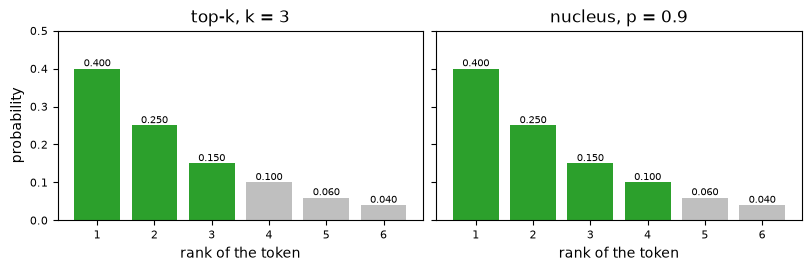

In [2]:
P = PEAKED
K = 3
TOP_P = 0.9
rules(P, K, TOP_P)

### Solution

In [3]:
peaked, flat = np.array(PEAKED), np.array(FLAT)
display(Markdown(f"On the peaked step k = 3 keeps {peaked[:3].sum():.2f} of the mass and the nucleus at p = 0.9 keeps "
                 f"{nucleus_size(peaked, 0.9)} tokens. On the flat step k = 3 keeps only {flat[:3].sum():.2f}, while "
                 f"the nucleus grows to all {nucleus_size(flat, 0.9)} tokens. Top-k keeps the same number of tokens "
                 "at every step; the nucleus keeps few where the model is sure and many where it is unsure. "
                 f"Renormalised, the first of the top three gets {peaked[0] / peaked[:3].sum():.2f}."))

On the peaked step k = 3 keeps 0.80 of the mass and the nucleus at p = 0.9 keeps 4 tokens. On the flat step k = 3 keeps only 0.57, while the nucleus grows to all 6 tokens. Top-k keeps the same number of tokens at every step; the nucleus keeps few where the model is sure and many where it is unsure. Renormalised, the first of the top three gets 0.50.

## 2. Temperature reshapes the distribution before a rule cuts it

A temperature below 1 sharpens the distribution and one above 1 flattens it.
Run the cell: how many tokens are in the nucleus at temperature 0.5, and how
many at temperature 1? Then set `TEMPERATURE` to 2 and run it again.

temperature 0.5: 0.615, 0.240, 0.086, 0.038, 0.014, 0.006
nucleus at p = 0.9: 4 tokens at temperature 1, 3 at temperature 0.5


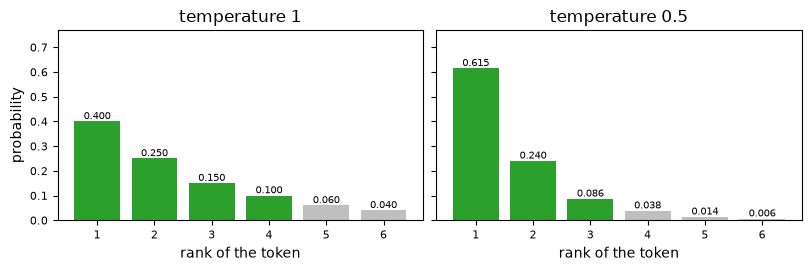

In [4]:
TEMPERATURE = 0.5  # the lecture's sharper panel; no model samples here, the cell only redraws six probabilities
temperature_bars(PEAKED, TEMPERATURE, 0.9)

### Solution

In [5]:
sharp, soft = with_temperature(PEAKED, 0.5), with_temperature(PEAKED, 2)
display(Markdown(f"At temperature 0.5 the first token rises from 0.40 to {sharp[0]:.3f} and the nucleus at p = 0.9 "
                 f"shrinks from 4 tokens to {nucleus_size(sharp, 0.9)}. At temperature 2 the first token falls to "
                 f"{soft[0]:.3f} and the nucleus grows to {nucleus_size(soft, 0.9)}. Temperature changes the "
                 "distribution, and top-k or the nucleus then cuts the changed one."))

At temperature 0.5 the first token rises from 0.40 to 0.615 and the nucleus at p = 0.9 shrinks from 4 tokens to 3. At temperature 2 the first token falls to 0.277 and the nucleus grows to 5. Temperature changes the distribution, and top-k or the nucleus then cuts the changed one.